# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Name:** Ayesha Liaqat  |  **Roll No:** FA23-BAI-054  |  **Course:** Computer Vision Lab

**My personal settings (from registration number 054):**

| Setting | Rule | My value |
|---|---|---|
| Random seed | last two digits | **54** |
| HOG cell size | last digit 4 is even | **8 x 8** |
| SIFT grid | last digit 4 is in 0 to 4 | **4 x 4 grid (16 keypoints)** |

In [1]:
# Install libraries (Colab already has most; medmnist downloads BloodMNIST automatically, no manual download needed)
!pip install -q medmnist scikit-image

## Personal settings cell
**What:** derive the three personal settings from the registration number with code, so nothing is typed by hand.
**Why:** the seed makes every random choice (which images are picked, noise, SVM) repeatable, so the same numbers appear every time the notebook runs.

In [2]:
import random
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt

REG_NO = "054"
SEED = int(REG_NO[-2:])                      # last two digits -> 54
last_digit = int(REG_NO[-1])                 # 4
HOG_CELL = (8, 8) if last_digit % 2 == 0 else (16, 16)   # even -> 8x8, odd -> 16x16
SIFT_GRID = 4 if last_digit <= 4 else 6      # 0-4 -> 4x4, 5-9 -> 6x6

random.seed(SEED)
np.random.seed(SEED)

print("Registration number:", REG_NO)
print("Seed               :", SEED)
print("HOG cell size      :", HOG_CELL)
print("SIFT grid          :", f"{SIFT_GRID} x {SIFT_GRID} = {SIFT_GRID**2} keypoints")

Registration number: 054
Seed               : 54
HOG cell size      : (8, 8)
SIFT grid          : 4 x 4 = 16 keypoints


# Q1. Data setup (3 marks)

**What:** load BloodMNIST (64x64 RGB), keep only 4 classes (eosinophil=1, monocyte=5, neutrophil=6, platelet=7), then randomly pick 100 train / 30 val / 30 test images per class using my seed. Then convert to grayscale and resize to 128x128.

**Why each step:**
- `medmnist` downloads the dataset by itself inside Colab, so I do not need to download anything manually.
- Only 4 classes and small subsets so the whole experiment runs fast on a normal laptop.
- `RandomState(SEED)` makes the chosen images the same on every run.
- Grayscale: HOG and SIFT both work on intensity gradients, they do not use colour.
- Resize to 128x128: all images need the same size, otherwise HOG gives different feature lengths. 128 is also divisible by 8 and by the SIFT grid steps.
- Train/val/test come from the *separate* official splits so there is no leakage between them.

In [3]:
from medmnist import BloodMNIST

raw = {s: BloodMNIST(split=s, download=True, size=64) for s in ["train", "val", "test"]}

KEEP = {1: "eosinophil", 5: "monocyte", 6: "neutrophil", 7: "platelet"}   # original label -> name
CLASS_NAMES = list(KEEP.values())
orig2new = {orig: new for new, orig in enumerate(KEEP)}                   # 1->0, 5->1, 6->2, 7->3
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}

rng = np.random.RandomState(SEED)

def make_subset(ds, n_per_class):
    imgs, labels = ds.imgs, ds.labels.ravel()
    X, y = [], []
    for orig in KEEP:
        idx = np.where(labels == orig)[0]
        chosen = rng.choice(idx, n_per_class, replace=False)
        for i in chosen:
            X.append(imgs[i])
            y.append(orig2new[orig])
    return np.array(X), np.array(y)

def prep(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.resize(gray, (128, 128), interpolation=cv2.INTER_LINEAR)

data = {}
for split in ["train", "val", "test"]:
    X_rgb, y = make_subset(raw[split], N_PER_CLASS[split])
    X = np.array([prep(im) for im in X_rgb])          # (N,128,128) uint8
    data[split] = (X, y)

Xtr, ytr = data["train"]; Xva, yva = data["val"]; Xte, yte = data["test"]

for split in ["train", "val", "test"]:
    X, y = data[split]
    counts = {CLASS_NAMES[c]: int((y == c).sum()) for c in range(4)}
    print(f"{split:5s} X shape: {X.shape}, y shape: {y.shape}, dtype: {X.dtype}, class counts: {counts}")

100%|██████████| 156M/156M [01:58<00:00, 1.32MB/s]


train X shape: (400, 128, 128), y shape: (400,), dtype: uint8, class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   X shape: (120, 128, 128), y shape: (120,), dtype: uint8, class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  X shape: (120, 128, 128), y shape: (120,), dtype: uint8, class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


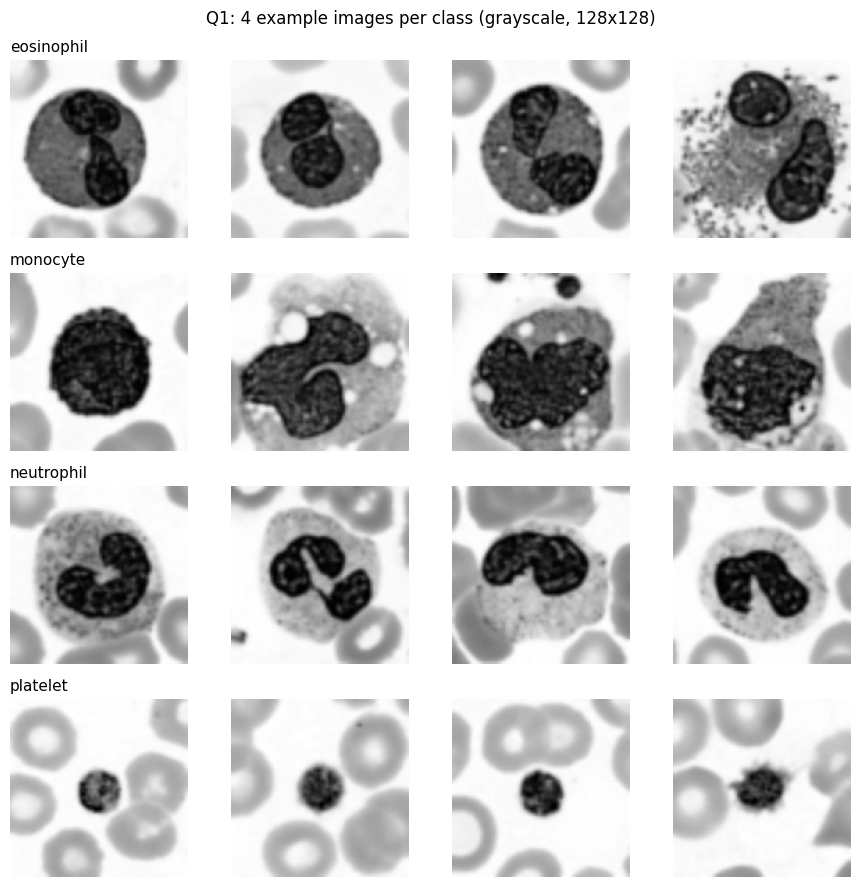

In [4]:
# Grid: 4 example images per class (training set)
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for c in range(4):
    idxs = np.where(ytr == c)[0][:4]
    for j, i in enumerate(idxs):
        axes[c, j].imshow(Xtr[i], cmap="gray")
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=11)
plt.suptitle("Q1: 4 example images per class (grayscale, 128x128)")
plt.tight_layout(); plt.show()

# Q2. HOG + SVM (6 marks)

**What is HOG?** Histogram of Oriented Gradients. The image is split into small cells (mine: 8x8 pixels). In each cell we build a histogram of gradient directions (9 bins). Cells are grouped into overlapping blocks (2x2 cells) and each block is normalised. All block histograms are joined into one long feature vector.

**Why HOG for cells?** It captures shape/edge structure (nucleus outline, granule texture) and is fairly stable to small brightness changes.

In [5]:
from skimage.feature import hog
from skimage import exposure

def hog_feat(img):
    return hog(img, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

def extract_hog(X):
    return np.array([hog_feat(im) for im in X])

H_tr, H_va = extract_hog(Xtr), extract_hog(Xva)
print("HOG feature matrix shapes -> train:", H_tr.shape, " val:", H_va.shape)
print("HOG feature length (from code):", H_tr.shape[1])

HOG feature matrix shapes -> train: (400, 8100)  val: (120, 8100)
HOG feature length (from code): 8100


### Q2 (2 marks): hand calculation of HOG feature length

Image = 128 x 128, cell = 8 x 8, block = 2 x 2 cells, 9 orientations.

1. Cells per side = 128 / 8 = **16**  (so 16 x 16 = 256 cells)
2. Blocks slide by 1 cell, so blocks per side = 16 - 2 + 1 = **15**  (so 15 x 15 = 225 blocks)
3. Values per block = 2 x 2 cells x 9 bins = **36**
4. Total length = 225 blocks x 36 = **8100**

(If the cell were 16 x 16 it would be 8 cells per side, 7 blocks per side, 49 x 36 = 1764.)

In [6]:
# Check the hand calculation against the real output
cells_per_side = 128 // HOG_CELL[0]
blocks_per_side = cells_per_side - 2 + 1
manual_len = blocks_per_side * blocks_per_side * 2 * 2 * 9
print(f"cells/side={cells_per_side}, blocks/side={blocks_per_side}, manual length={manual_len}")
print("Matches code output:", manual_len == H_tr.shape[1])

cells/side=16, blocks/side=15, manual length=8100
Matches code output: True


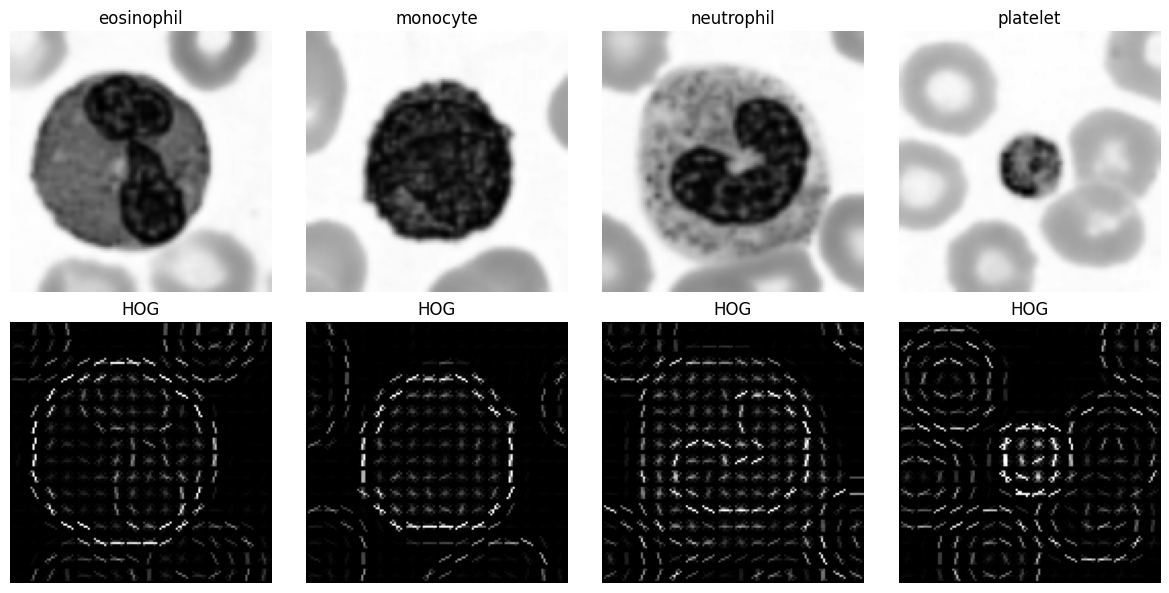

In [7]:
# Q2 (1 mark): HOG picture for one image of each class
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for c in range(4):
    img = Xtr[np.where(ytr == c)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2),
                     block_norm="L2-Hys", visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, np.percentile(hog_img, 99.5) + 1e-9))
    axes[0, c].imshow(img, cmap="gray");     axes[0, c].set_title(CLASS_NAMES[c]); axes[0, c].axis("off")
    axes[1, c].imshow(hog_img, cmap="gray"); axes[1, c].set_title("HOG");          axes[1, c].axis("off")
plt.tight_layout(); plt.show()

### Training the SVM (shared helper used for HOG and SIFT)

**What:** `LinearSVC` is a linear Support Vector Machine. I train it with C = 0.1, 1, 10 on the **train** set, compare accuracy on the **validation** set, and keep the best C.

**Why:**
- C controls the trade-off between a wide margin (small C, more regularisation) and fitting training points exactly (large C).
- The validation set is used to choose C so the test set stays untouched until Q4 (otherwise the test result would be biased).
- `dual=True` is used because there are many more features than samples. `random_state=SEED` keeps it repeatable.
- Ties are broken in favour of the smaller C (simpler model).
- Metrics: accuracy = overall correct; **macro-F1** = average F1 of each class, treating all classes equally; **confusion matrix** = rows are true class, columns are predicted class.

In [8]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

C_GRID = [0.1, 1, 10]

def select_C_and_train(Xtr_f, ytr, Xva_f, yva):
    best = None
    rows = []
    for C in C_GRID:
        model = LinearSVC(C=C, dual=True, random_state=SEED, max_iter=20000).fit(Xtr_f, ytr)
        acc = accuracy_score(yva, model.predict(Xva_f))
        rows.append({"C": C, "val_accuracy": round(acc, 4)})
        if best is None or acc > best[1]:
            best = (C, acc, model)
    print(pd.DataFrame(rows).to_string(index=False))
    print(f"--> Best C on validation set: {best[0]}")
    return best[2], best[0]

def report(model, Xf, y, title):
    pred = model.predict(Xf)
    acc = accuracy_score(y, pred)
    f1 = f1_score(y, pred, average="macro")
    cm = confusion_matrix(y, pred)
    print(f"{title}\nValidation accuracy: {acc:.4f}\nValidation macro-F1: {f1:.4f}\nConfusion matrix (rows=true, cols=pred):\n{cm}")
    fig, ax = plt.subplots(figsize=(5, 5))
    ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=CLASS_NAMES, cmap="Blues", ax=ax, xticks_rotation=45)
    ax.set_title(title); plt.tight_layout(); plt.show()
    return cm

   C  val_accuracy
 0.1        0.6667
 1.0        0.6667
10.0        0.6667
--> Best C on validation set: 0.1
HOG + SVM (validation)
Validation accuracy: 0.6667
Validation macro-F1: 0.6625
Confusion matrix (rows=true, cols=pred):
[[17 11  2  0]
 [ 3 22  5  0]
 [11  7 12  0]
 [ 0  1  0 29]]


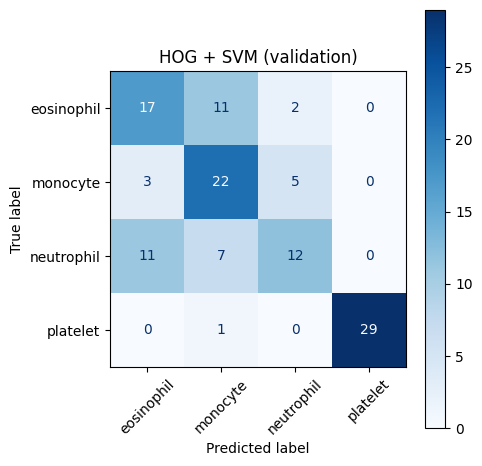

In [9]:
hog_model, hog_C = select_C_and_train(H_tr, ytr, H_va, yva)
hog_cm = report(hog_model, H_va, yva, "HOG + SVM (validation)")

# Q3. SIFT + SVM (7 marks)

**What is SIFT?** Scale-Invariant Feature Transform. It finds interesting points (keypoints, such as blobs and corners) and describes the neighbourhood of each one with a **128-number descriptor** (gradient histograms in a 4x4 grid x 8 directions).

**Normal SIFT problem:** `detectAndCompute` finds a *different number* of keypoints in every image, so each image would give a descriptor matrix of a different size.

In [10]:
sift = cv2.SIFT_create()

kp_counts = []
for im in Xtr:
    kps, des = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)

print(f"Average keypoints per image: {kp_counts.mean():.2f}")
print(f"Minimum keypoints per image: {kp_counts.min()}")
print(f"Maximum keypoints per image: {kp_counts.max()}")
print(f"Images with zero keypoints : {(kp_counts == 0).sum()} out of {len(kp_counts)}")

Average keypoints per image: 71.22
Minimum keypoints per image: 7
Maximum keypoints per image: 294
Images with zero keypoints : 0 out of 400


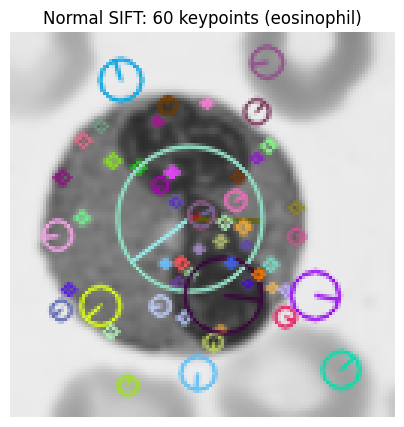

In [11]:
# Draw keypoints on one training image (first image that has keypoints)
i = int(np.where(kp_counts > 0)[0][0])
kps, _ = sift.detectAndCompute(Xtr[i], None)
vis = cv2.drawKeypoints(Xtr[i], kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"Normal SIFT: {len(kps)} keypoints ({CLASS_NAMES[ytr[i]]})"); plt.show()

**Why a different number of keypoints is a problem for an SVM (one sentence):**
An SVM needs every image to be a feature vector of the *same length* (a fixed number of columns), but if one image has 40 keypoints and another has 120, their joined descriptors have different lengths (40 x 128 vs 120 x 128) and also the keypoints are not in matching positions, so they cannot be stacked into one matrix or compared feature by feature.

### Fix: fixed grid of keypoints ("dense SIFT")
**What:** instead of letting SIFT detect keypoints, I place keypoints myself on a regular **4 x 4 grid** (16 points) over the 128x128 image, each with keypoint size 32, and compute the descriptor at each point with `sift.compute`.

**Why:** every image now has exactly 16 keypoints in the same places, so each image gives 16 x 128 numbers, which is a fixed-length vector. Size 32 means each descriptor looks at a 32x32 patch, and 4 grid points per side spaced 32 px apart cover the whole image without gaps. Points are placed at the centre of each grid cell: 16, 48, 80, 112.

**Extra step:** each 128-number descriptor is L2-normalised (divided by its length) so no descriptor dominates the SVM just because it has large values.

SIFT feature matrix shapes -> train: (400, 2048)  val: (120, 2048)
SIFT feature length (from code): 2048


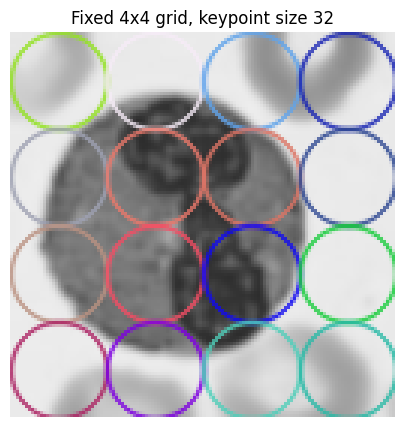

In [12]:
KP_SIZE = 32

def make_grid_keypoints(grid=SIFT_GRID, img_size=128, kp_size=KP_SIZE):
    step = img_size / grid
    return [cv2.KeyPoint(float((j + 0.5) * step), float((i + 0.5) * step), kp_size)
            for i in range(grid) for j in range(grid)]

def sift_grid_feat(img):
    kps = make_grid_keypoints()                 # fresh list each call (compute can modify it)
    kps, des = sift.compute(img, kps)
    n_expected = SIFT_GRID * SIFT_GRID
    if des is None or des.shape[0] != n_expected:          # safety: keep fixed length
        return np.zeros(n_expected * 128, dtype=np.float32)
    des = des / (np.linalg.norm(des, axis=1, keepdims=True) + 1e-7)
    return des.flatten()

def extract_sift(X):
    return np.array([sift_grid_feat(im) for im in X])

S_tr, S_va = extract_sift(Xtr), extract_sift(Xva)
print("SIFT feature matrix shapes -> train:", S_tr.shape, " val:", S_va.shape)
print("SIFT feature length (from code):", S_tr.shape[1])

# show the grid on one image
vis = cv2.drawKeypoints(Xtr[0], make_grid_keypoints(), None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"Fixed {SIFT_GRID}x{SIFT_GRID} grid, keypoint size {KP_SIZE}"); plt.show()

### Q3 (2 marks): hand calculation of SIFT feature length

- Grid = 4 x 4 = **16 grid points** (keypoints)
- Each SIFT descriptor = 128 numbers (4 x 4 spatial bins x 8 orientation bins)
- Total length = 16 x 128 = **2048**

In [13]:
manual_len = SIFT_GRID * SIFT_GRID * 128
print(f"{SIFT_GRID*SIFT_GRID} grid points x 128 = {manual_len}")
print("Matches code output:", manual_len == S_tr.shape[1])

16 grid points x 128 = 2048
Matches code output: True


   C  val_accuracy
 0.1        0.7250
 1.0        0.7667
10.0        0.7167
--> Best C on validation set: 1
SIFT (grid) + SVM (validation)
Validation accuracy: 0.7667
Validation macro-F1: 0.7667
Confusion matrix (rows=true, cols=pred):
[[18  7  5  0]
 [ 8 21  1  0]
 [ 3  2 24  1]
 [ 1  0  0 29]]


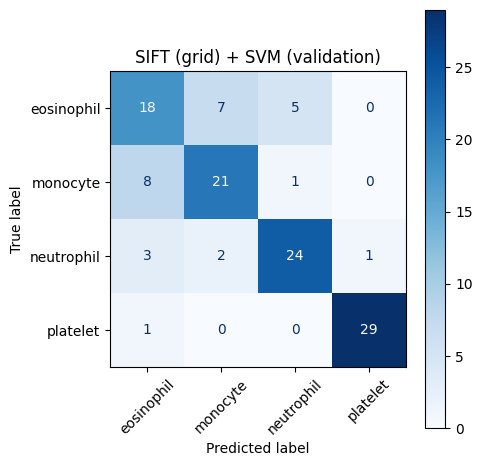

In [14]:
sift_model, sift_C = select_C_and_train(S_tr, ytr, S_va, yva)
sift_cm = report(sift_model, S_va, yva, "SIFT (grid) + SVM (validation)")

# Q4. Robustness (6 marks)

### Q4 (1 mark): My prediction (written BEFORE running the test evaluation)

> **EDIT THIS CELL IN YOUR OWN WORDS before you run the cells below.**

- **Rotation:** I think **HOG** will lose more accuracy. Reason: HOG histograms are tied to fixed positions and fixed gradient directions, so rotating the cell changes which orientation bin and which cell the edges fall in, and my fixed-grid SIFT looks at big 32x32 patches that change less when the picture is turned 20 degrees.
- **Noise:** I think **HOG** will lose more accuracy. Reason: Gaussian noise creates many tiny random gradients in every pixel, which fill HOG's small 8x8 cells with fake edges, while SIFT's size-32 patches are Gaussian-weighted and average out the noise.

### How the robustness test works (what and why)
- **Freeze both models:** I do not retrain. The same `hog_model` and `sift_model` (trained on clean train images, C chosen on validation) are used for all three cases.
- **Rotation 20 degrees:** `cv2.getRotationMatrix2D` around the image centre (64, 64) then `cv2.warpAffine`. Empty corners become black.
- **Gaussian noise sigma = 0.05:** image is scaled to 0..1, noise from N(0, 0.05) is added, values are clipped back to 0..1, then converted back to 0..255 for SIFT. A seeded generator makes the noise repeatable.
- **Change first, features second:** the change is applied to the images *before* feature extraction, exactly as the question says.
- This is the first time the **test set** is used.

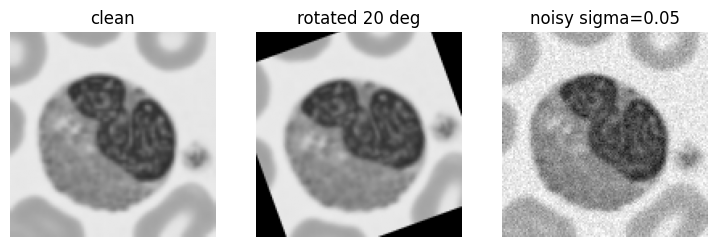

In [15]:
def rotate_img(img, angle=20):
    M = cv2.getRotationMatrix2D((64, 64), angle, 1.0)
    return cv2.warpAffine(img, M, (128, 128), flags=cv2.INTER_LINEAR, borderValue=0)

noise_rng = np.random.RandomState(SEED)
def noisy_img(img, sigma=0.05):
    x = img.astype(np.float32) / 255.0
    x = np.clip(x + noise_rng.normal(0, sigma, x.shape), 0, 1)
    return (x * 255).round().astype(np.uint8)

# quick look at the transformed images
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, t in zip(axes, [Xte[0], rotate_img(Xte[0]), noisy_img(Xte[0])], ["clean", "rotated 20 deg", "noisy sigma=0.05"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.show()

In [16]:
conditions = {
    "clean":   lambda X: X,
    "rotated": lambda X: np.array([rotate_img(im) for im in X]),
    "noisy":   lambda X: np.array([noisy_img(im) for im in X]),
}
models = {
    "HOG + SVM":  (hog_model,  extract_hog),
    "SIFT + SVM": (sift_model, extract_sift),
}

results = {}
for mname, (model, extractor) in models.items():
    results[mname] = {}
    for cname, transform in conditions.items():
        Xt = transform(Xte)                       # change images first
        feats = extractor(Xt)                     # then extract features
        results[mname][cname] = accuracy_score(yte, model.predict(feats))

table = pd.DataFrame(results).T[["clean", "rotated", "noisy"]]
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
table.index.name = "Model"
table["Drop (rotation)"] = table["Clean accuracy"] - table["Rotated accuracy"]
table["Drop (noise)"]    = table["Clean accuracy"] - table["Noisy accuracy"]
print("Test set accuracy (120 test images):")
display(table.round(4))

Test set accuracy (120 test images):


,Clean accuracy,Rotated accuracy,Noisy accuracy,Drop (rotation),Drop (noise)
Model,,,,,
HOG + SVM,0.7167,0.70,0.5917,0.0167,0.125
SIFT + SVM,0.8083,0.55,0.7833,0.2583,0.025


### Q4 (1 mark): Was my prediction correct?

> **WRITE THIS AFTER LOOKING AT THE TABLE ABOVE. Exactly three sentences, using your own numbers.**
>
> Template (replace XX with numbers from the table and fix the words if your result was different):
> Under rotation, [HOG/SIFT] lost the most accuracy, dropping from XX to XX, so my rotation prediction was [correct/wrong]. Under noise, [HOG/SIFT] dropped from XX to XX while [the other model] dropped from XX to XX, so my noise prediction was [correct/wrong]. This happens because [one reason linked to the numbers, e.g. HOG cell histograms depend on exact edge directions / SIFT patches of size 32 smooth the noise].

# Q5. Short answers and AI log (3 marks)

### (a) Why does HOG use block normalisation?
Different parts of an image can have very different brightness and contrast, which changes the size of the gradients even when the shape is the same. Block normalisation divides each block's histogram by its own length, so the feature depends on the *pattern* of edges and not on how bright or contrasty that area is. This makes HOG more stable to lighting changes, and the overlapping blocks also let each cell be normalised in several contexts.

### (b) Why is it wrong to choose C using the test set?
The test set must act like new, unseen data to give an honest estimate of how the model will do in real life. If I pick the C that scores best on the test set, then the test set has influenced my model, so the reported accuracy becomes too optimistic (information leakage / overfitting to the test set). C must be chosen on the validation set, and the test set used only once at the end.

### Which two classes were confused most? (computed from the validation confusion matrices)

In [17]:
def most_confused(cm):
    off = cm.copy().astype(int)
    np.fill_diagonal(off, 0)
    pair_scores = {}
    for i in range(4):
        for j in range(i + 1, 4):
            pair_scores[(i, j)] = off[i, j] + off[j, i]          # both directions
    (i, j), total = max(pair_scores.items(), key=lambda kv: kv[1])
    return CLASS_NAMES[i], CLASS_NAMES[j], total

for name, cm in [("HOG + SVM", hog_cm), ("SIFT + SVM", sift_cm)]:
    a, b, n = most_confused(cm)
    print(f"{name}: most confused pair = {a} <-> {b} ({n} mistakes in total, both directions)")

HOG + SVM: most confused pair = eosinophil <-> monocyte (14 mistakes in total, both directions)
SIFT + SVM: most confused pair = eosinophil <-> monocyte (15 mistakes in total, both directions)
